<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week7_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL P7 - SEGMENTASI CITRA DENGAN THRESHOLDING
## Tugas Individu
**Nama:** Rifo Anggi Barbara Danuarta  
**NIM:** 244107020063  
**Kelas:** 3F  
**No. Absen:** 24

In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, segmentation

np.set_printoptions(suppress=True)
plt.rcParams['figure.figsize'] = (12, 6)

def tampilkan(images, titles, cols=3, figsize=None):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=figsize or (5 * cols, 4 * rows))
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if image.ndim == 3:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(image, cmap='gray')
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def baca_grayscale(path):
    image = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f'Citra tidak ditemukan atau tidak dapat dibaca: {path}')
    return image

print('OpenCV:', cv.__version__)

OpenCV: 5.0.0


## Persiapan Citra


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/PCVK_2026'

def cari_citra(kandidat):
    for path in kandidat:
        if os.path.exists(path):
            return path
    return kandidat[0]

PATH_LENA = cari_citra([
    os.path.join(BASE, 'lena_gs_lc2.jpg'),
    os.path.join(BASE, 'lena_lc.jpg'),
    os.path.join(BASE, 'lena.jpg'),
    '/content/lena_gs_lc2.jpg',
    '/content/lena_lc.jpg',
    '/content/lena.jpg',
])
PATH_SUDOKU = cari_citra([
    os.path.join(BASE, 'sudoku-original.jpg'),
    os.path.join(BASE, 'sudoku.jpg'),
    '/content/sudoku-original.jpg',
])
PATH_KTP = cari_citra([
    os.path.join(BASE, 'ktp_fulan.jpg'),
    os.path.join(BASE, 'ktp.jpg'),
    '/content/ktp_fulan.jpg',
])

print('Lena  :', PATH_LENA, '(ada)' if os.path.exists(PATH_LENA) else '(belum ada)')
print('Sudoku:', PATH_SUDOKU, '(ada)' if os.path.exists(PATH_SUDOKU) else '(belum ada)')
print('KTP   :', PATH_KTP, '(ada)' if os.path.exists(PATH_KTP) else '(belum ada)')
print('Catatan: jika path belum ada, unggah file lalu ubah variabel path.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lena  : /content/drive/MyDrive/PCVK_2026/lena.jpg (ada)
Sudoku: /content/drive/MyDrive/PCVK_2026/sudoku-original.jpg (ada)
KTP   : /content/drive/MyDrive/PCVK_2026/ktp_fulan.jpg (ada)
Catatan: jika path belum ada, unggah file lalu ubah variabel path.


## 1. Global Threshold Manual

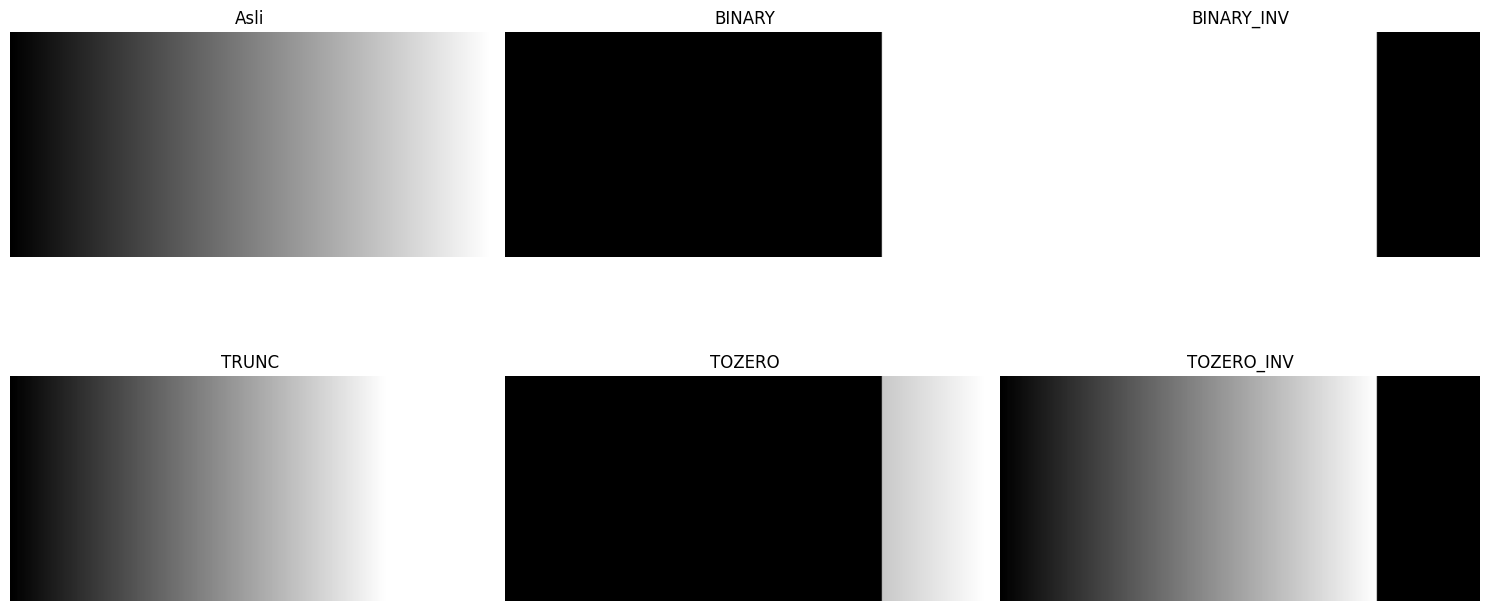

In [ ]:
# Citra gradient dibuat agar efek kelima jenis threshold terlihat jelas.
gradient = np.tile(np.arange(256, dtype=np.uint8), (120, 1))
thresh = 200
maxval = 255

def global_threshold_manual(image, threshold=200, max_value=255, jenis='BINARY'):
    image = image.astype(np.uint8)
    result = image.copy()
    lebih = image > threshold
    if jenis == 'BINARY':
        result = np.where(lebih, max_value, 0)
    elif jenis == 'BINARY_INV':
        result = np.where(lebih, 0, max_value)
    elif jenis == 'TRUNC':
        result = np.where(lebih, threshold, image)
    elif jenis == 'TOZERO':
        result = np.where(lebih, image, 0)
    elif jenis == 'TOZERO_INV':
        result = np.where(lebih, 0, image)
    else:
        raise ValueError('Jenis threshold tidak dikenal.')
    return result.astype(np.uint8)

jenis_global = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil_global = [global_threshold_manual(gradient, thresh, maxval, jenis) for jenis in jenis_global]
tampilkan([gradient] + hasil_global, ['Asli'] + jenis_global, cols=3, figsize=(15, 8))

## 2. Adaptive Threshold Manual

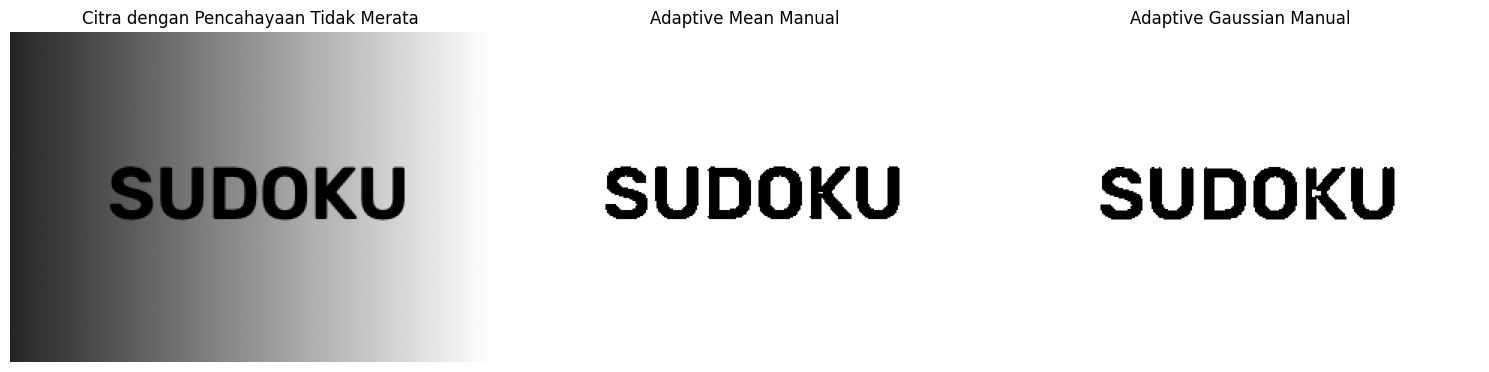

In [ ]:
def gaussian_kernel_manual(size=11, sigma=2):
    radius = size // 2
    y, x = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    kernel = np.exp(-(x*x + y*y) / (2 * sigma*sigma))
    return kernel / kernel.sum()

def adaptive_mean_manual(gray, block_size=11, C=2):
    radius = block_size // 2
    padded = np.pad(gray.astype(np.float32), radius, mode='reflect')
    integral = np.pad(padded, ((1, 0), (1, 0)), mode='constant')
    integral = integral.cumsum(axis=0).cumsum(axis=1)
    local_sum = (integral[block_size:, block_size:] - integral[:-block_size, block_size:]
                 - integral[block_size:, :-block_size] + integral[:-block_size, :-block_size])
    local_mean = local_sum / (block_size * block_size)
    return np.where(gray > local_mean - C, 255, 0).astype(np.uint8)

def adaptive_gaussian_manual(gray, block_size=11, C=2, sigma=2):
    radius = block_size // 2
    padded = np.pad(gray.astype(np.float32), radius, mode='reflect')
    kernel = gaussian_kernel_manual(block_size, sigma)
    local_mean = np.zeros_like(gray, dtype=np.float32)
    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            window = padded[y:y + block_size, x:x + block_size]
            local_mean[y, x] = np.sum(window * kernel)
    return np.where(gray > local_mean - C, 255, 0).astype(np.uint8)

# Citra demo dengan pencahayaan tidak merata agar notebook tetap dapat dijalankan.
demo = np.tile(np.linspace(50, 220, 320, dtype=np.uint8), (220, 1))
cv.putText(demo, 'SUDOKU', (65, 125), cv.FONT_HERSHEY_SIMPLEX, 1.7, 20, 4)
adaptive_mean = adaptive_mean_manual(demo, 11, 2)
adaptive_gaussian = adaptive_gaussian_manual(demo, 11, 2, 2)
tampilkan([demo, adaptive_mean, adaptive_gaussian], ['Citra dengan Pencahayaan Tidak Merata', 'Adaptive Mean Manual', 'Adaptive Gaussian Manual'], cols=3)

### Adaptive Threshold pada Citra Sudoku

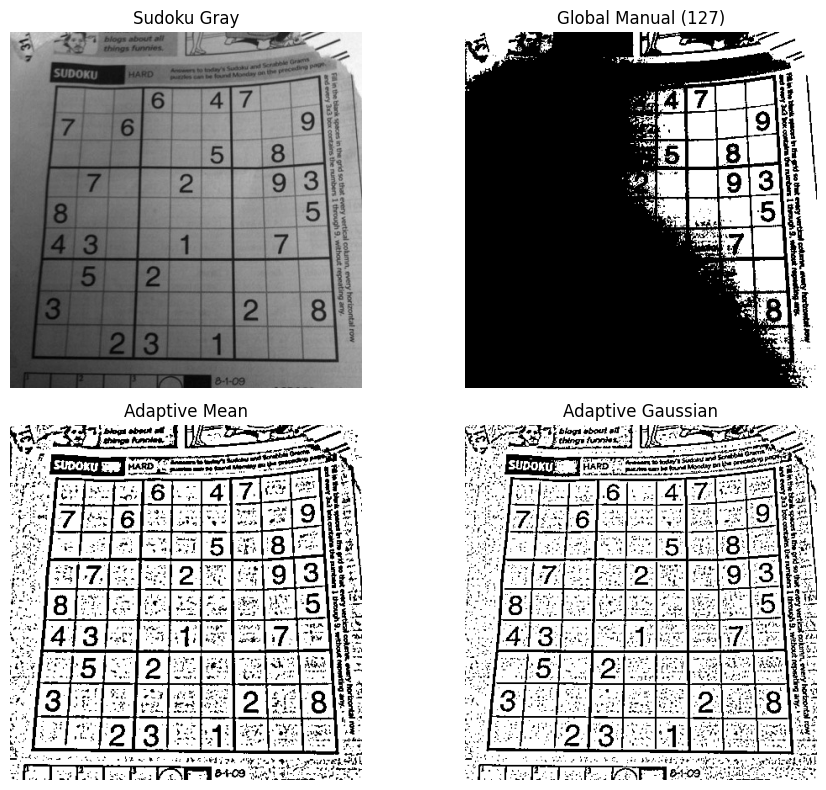

In [ ]:
if os.path.exists(PATH_SUDOKU):
    sudoku = baca_grayscale(PATH_SUDOKU)
    sudoku_mean = adaptive_mean_manual(sudoku, 11, 2)
    sudoku_gaussian = adaptive_gaussian_manual(sudoku, 11, 2, 2)
    sudoku_global = global_threshold_manual(sudoku, 127, 255, 'BINARY')
    tampilkan([sudoku, sudoku_global, sudoku_mean, sudoku_gaussian], ['Sudoku Gray', 'Global Manual (127)', 'Adaptive Mean', 'Adaptive Gaussian'], cols=2)
else:
    print('PATH_SUDOKU belum tersedia. Unggah sudoku-original.jpg dan jalankan kembali sel ini.')

## 3. Otsu Threshold Manual

Citra Lena: shape=(512, 512), dtype=uint8, 2D grayscale=True
Rentang intensitas Lena grayscale: 0 sampai 255
Rentang kontras rendah: 85 sampai 108 (semua < 127)
Threshold Otsu pada citra kontras rendah: 94


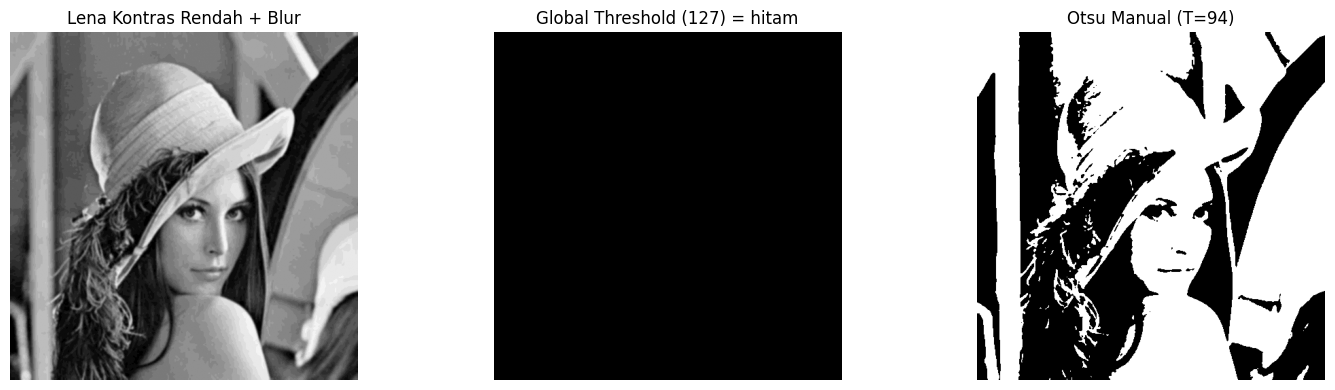

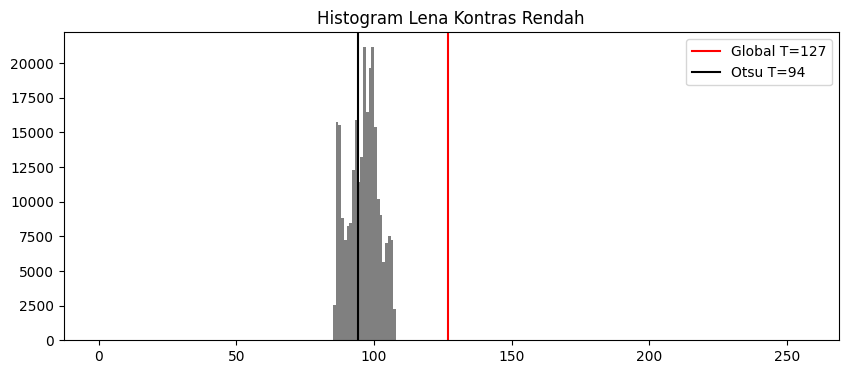

Threshold Otsu Lena asli: 113
Jawaban: agar objek Lena tetap terlihat, gunakan ambang sekitar 94 (Otsu) yang berada di dalam rentang intensitas, bukan 127.


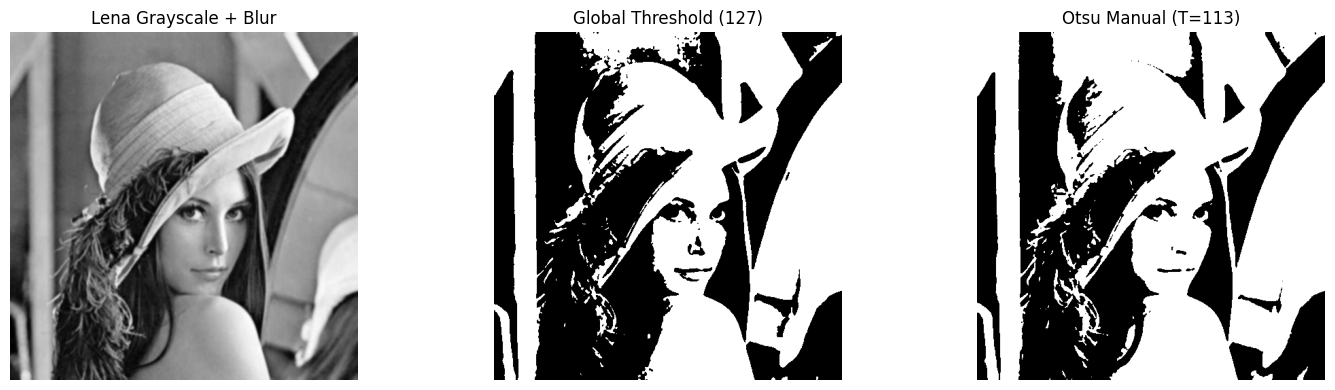

In [ ]:
def otsu_manual(gray):
    gray = gray.astype(np.uint8)
    histogram = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    total = gray.size
    nilai = np.arange(256, dtype=np.float64)
    total_sum = np.sum(nilai * histogram)
    weight_background = 0.0
    sum_background = 0.0
    best_threshold = 0
    best_variance = -1.0
    for t in range(256):
        weight_background += histogram[t] / total
        sum_background += t * histogram[t] / total
        weight_foreground = 1.0 - weight_background
        if weight_background == 0 or weight_foreground == 0:
            continue
        mean_background = sum_background / weight_background
        mean_total = total_sum / total
        mean_foreground = (mean_total - sum_background) / weight_foreground
        variance_between = (weight_background * weight_foreground *
                           (mean_background - mean_foreground) ** 2)
        if variance_between > best_variance:
            best_variance = variance_between
            best_threshold = t
    binary = np.where(gray > best_threshold, 255, 0).astype(np.uint8)
    return binary, best_threshold

def jadikan_kontras_rendah(gray, low=85, high=108):
    gray_f = gray.astype(np.float32)
    lo, hi = float(gray_f.min()), float(gray_f.max())
    if hi <= lo:
        return np.full_like(gray, low, dtype=np.uint8)
    skala = (gray_f - lo) / (hi - lo)
    return (low + skala * (high - low)).astype(np.uint8)

if os.path.exists(PATH_LENA):
    lena = baca_grayscale(PATH_LENA)   # citra warna apa pun langsung dikonversi ke grayscale
    print(f'Citra Lena: shape={lena.shape}, dtype={lena.dtype}, 2D grayscale={lena.ndim == 2}')
    print(f'Rentang intensitas Lena grayscale: {lena.min()} sampai {lena.max()}')

    # Versi kontras rendah meniru lena_gs_lc2.jpg (seluruh intensitas di bawah 127).
    lena_lc = jadikan_kontras_rendah(lena, 85, 108)
    lena_lc_blur = cv.GaussianBlur(lena_lc, (5, 5), 0)
    lc_global = global_threshold_manual(lena_lc_blur, 127, 255, 'BINARY')
    lc_otsu, lc_t = otsu_manual(lena_lc_blur)
    print(f'Rentang kontras rendah: {lena_lc_blur.min()} sampai {lena_lc_blur.max()} (semua < 127)')
    print(f'Threshold Otsu pada citra kontras rendah: {lc_t}')
    tampilkan([lena_lc_blur, lc_global, lc_otsu], ['Lena Kontras Rendah + Blur', 'Global Threshold (127) = hitam', f'Otsu Manual (T={lc_t})'], cols=3)
    plt.figure(figsize=(10, 4))
    plt.hist(lena_lc_blur.ravel(), bins=256, range=(0, 256), color='gray')
    plt.axvline(127, color='red', label='Global T=127')
    plt.axvline(lc_t, color='black', label=f'Otsu T={lc_t}')
    plt.title('Histogram Lena Kontras Rendah')
    plt.legend()
    plt.show()

    # Pembanding: Otsu pada citra Lena grayscale apa adanya.
    lena_blur = cv.GaussianBlur(lena, (5, 5), 0)
    lena_otsu, lena_t = otsu_manual(lena_blur)
    lena_global = global_threshold_manual(lena_blur, 127, 255, 'BINARY')
    print(f'Threshold Otsu Lena asli: {lena_t}')
    print(f'Jawaban: agar objek Lena tetap terlihat, gunakan ambang sekitar {lc_t} (Otsu) yang berada di dalam rentang intensitas, bukan 127.')
    tampilkan([lena_blur, lena_global, lena_otsu], ['Lena Grayscale + Blur', 'Global Threshold (127)', f'Otsu Manual (T={lena_t})'], cols=3)
else:
    print('PATH_LENA belum tersedia. Unggah lena.jpg (atau lena_gs_lc2.jpg) lalu jalankan ulang sel ini.')

Threshold Otsu OpenCV: 113


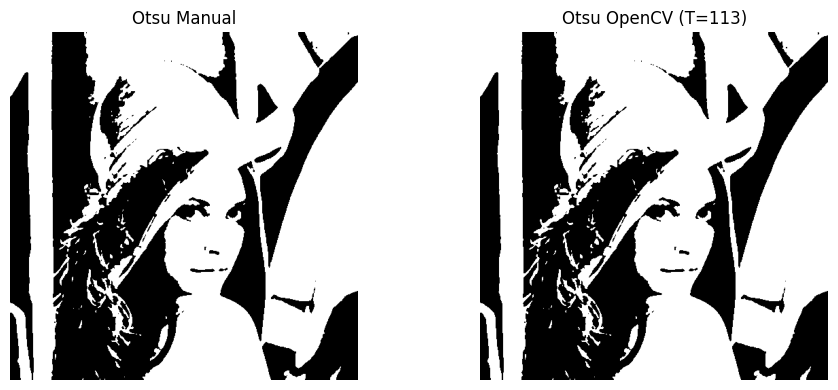

In [ ]:
# cv.threshold mengembalikan (retval, dst): retval = nilai ambang, dst = citra biner.
if os.path.exists(PATH_LENA):
    library_t, library_binary = cv.threshold(lena_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    library_t = int(library_t)
    print(f'Threshold Otsu OpenCV: {library_t}')
    tampilkan([lena_otsu, library_binary], ['Otsu Manual', f'Otsu OpenCV (T={library_t})'], cols=2)
else:
    print('Jalankan sel Otsu manual setelah citra Lena tersedia.')

**Analisis Lena (Tugas 3):** Pada citra Lena kontras rendah (mis. rentang 85-108 seperti `lena_gs_lc2.jpg`), seluruh piksel bernilai di bawah 127. Karena Binary Threshold hanya mengubah piksel bernilai `> 127` menjadi putih, tidak ada satu pun piksel yang memenuhi syarat, sehingga seluruh citra menjadi 0 (hitam semua). Pada histogram, seluruh batang berada di sebelah kiri garis merah T=127. Agar objek Lena tetap terlihat, ambang harus berada di dalam rentang intensitas citra, yaitu sekitar nilai Otsu (di bawah 108), bukan 127. Nilai Otsu yang dipakai tercetak pada output sel di atas. Karena `lena.jpg` asli memiliki kontras penuh (0-255), citra kontras rendah dibuat otomatis pada sel di atas agar kasus ini dapat dibuktikan.

### Otsu pada Citra KTP (Tugas 5B)


Threshold Otsu KTP: 150
Rentang intensitas KTP: 0 sampai 255


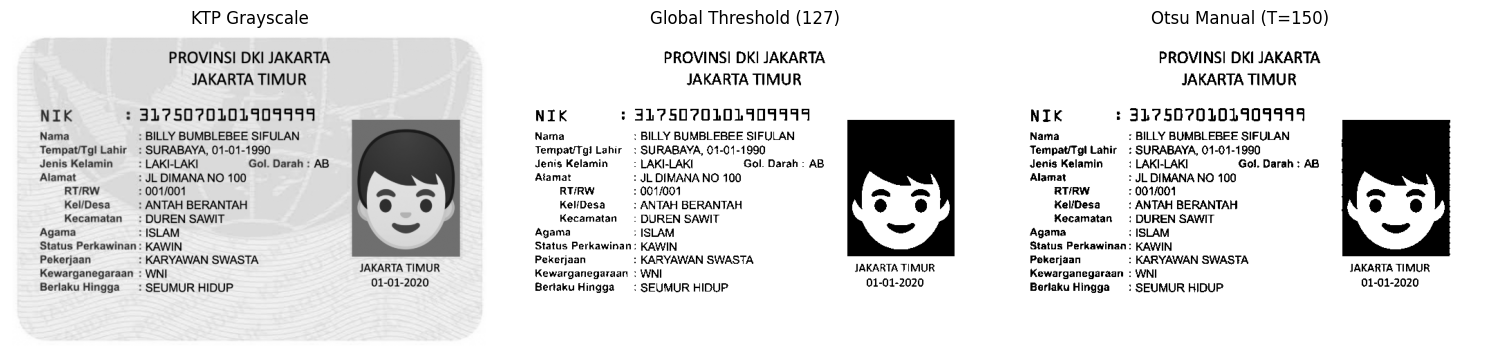

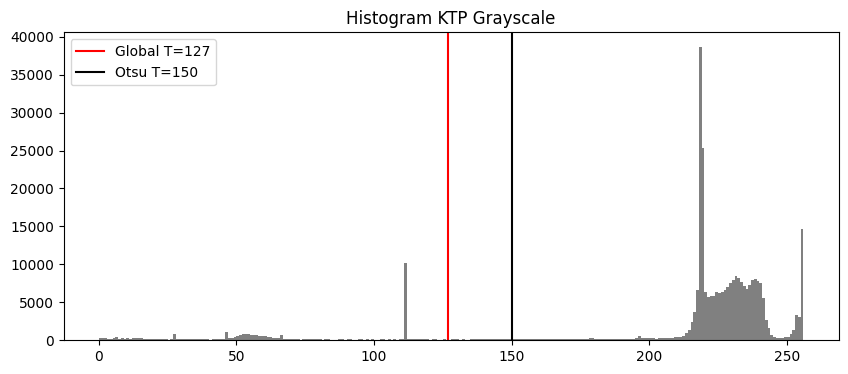

In [ ]:
if os.path.exists(PATH_KTP):
    ktp_gray = baca_grayscale(PATH_KTP)
    ktp_otsu, ktp_t = otsu_manual(ktp_gray)
    ktp_global = global_threshold_manual(ktp_gray, 127, 255, 'BINARY')
    print(f'Threshold Otsu KTP: {ktp_t}')
    print(f'Rentang intensitas KTP: {ktp_gray.min()} sampai {ktp_gray.max()}')
    tampilkan([ktp_gray, ktp_global, ktp_otsu], ['KTP Grayscale', 'Global Threshold (127)', f'Otsu Manual (T={ktp_t})'], cols=3)
    plt.figure(figsize=(10, 4))
    plt.hist(ktp_gray.ravel(), bins=256, range=(0, 256), color='gray')
    plt.axvline(127, color='red', label='Global T=127')
    plt.axvline(ktp_t, color='black', label=f'Otsu T={ktp_t}')
    plt.title('Histogram KTP Grayscale')
    plt.legend()
    plt.show()
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg untuk mengerjakan Tugas 5B.')

**Analisis KTP (Tugas 5B):** Berbeda dengan citra Lena kontras rendah, citra KTP umumnya memiliki kontras dan pencahayaan yang tidak merata. Global threshold dengan ambang tetap 127 sering gagal memisahkan teks dari latar (sebagian area menjadi hitam total atau putih total). Otsu menghitung ambang otomatis dari histogram sehingga pemisahan objek dan latar lebih baik. Bandingkan nilai `ktp_t` (Otsu) dengan 127 pada output di atas untuk melihat perbedaannya.

## 4. Segmentasi Berbasis Region pada `data.coins()`


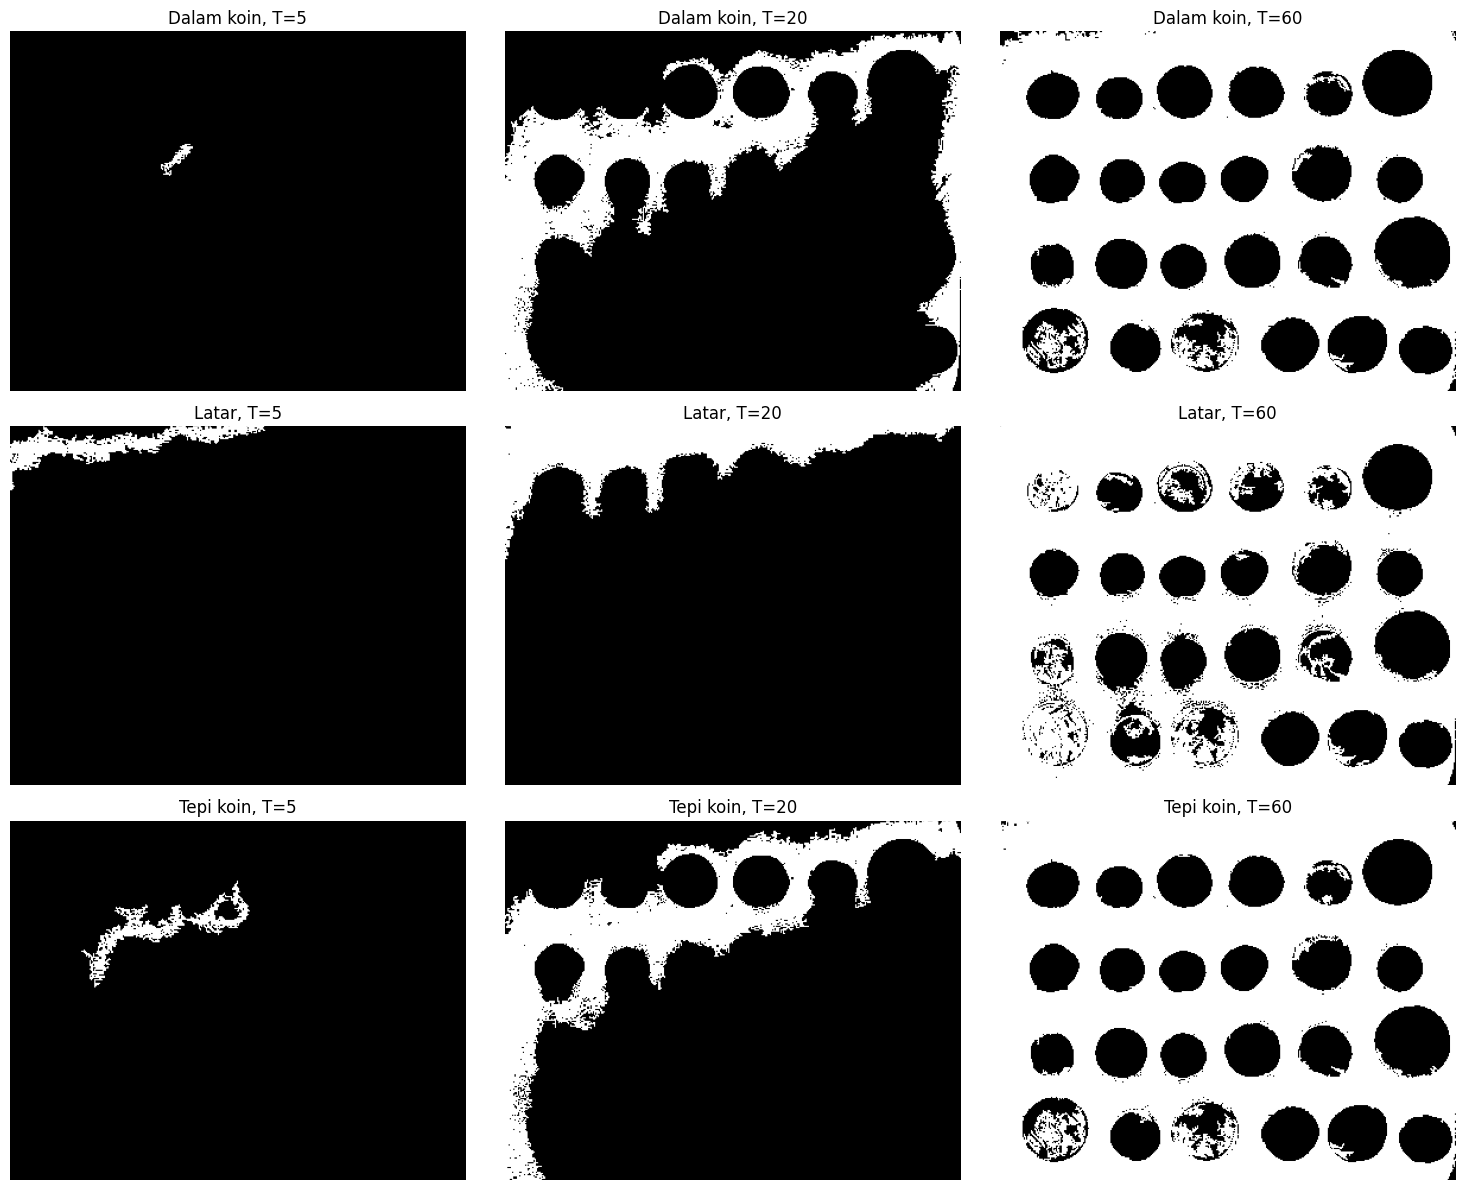

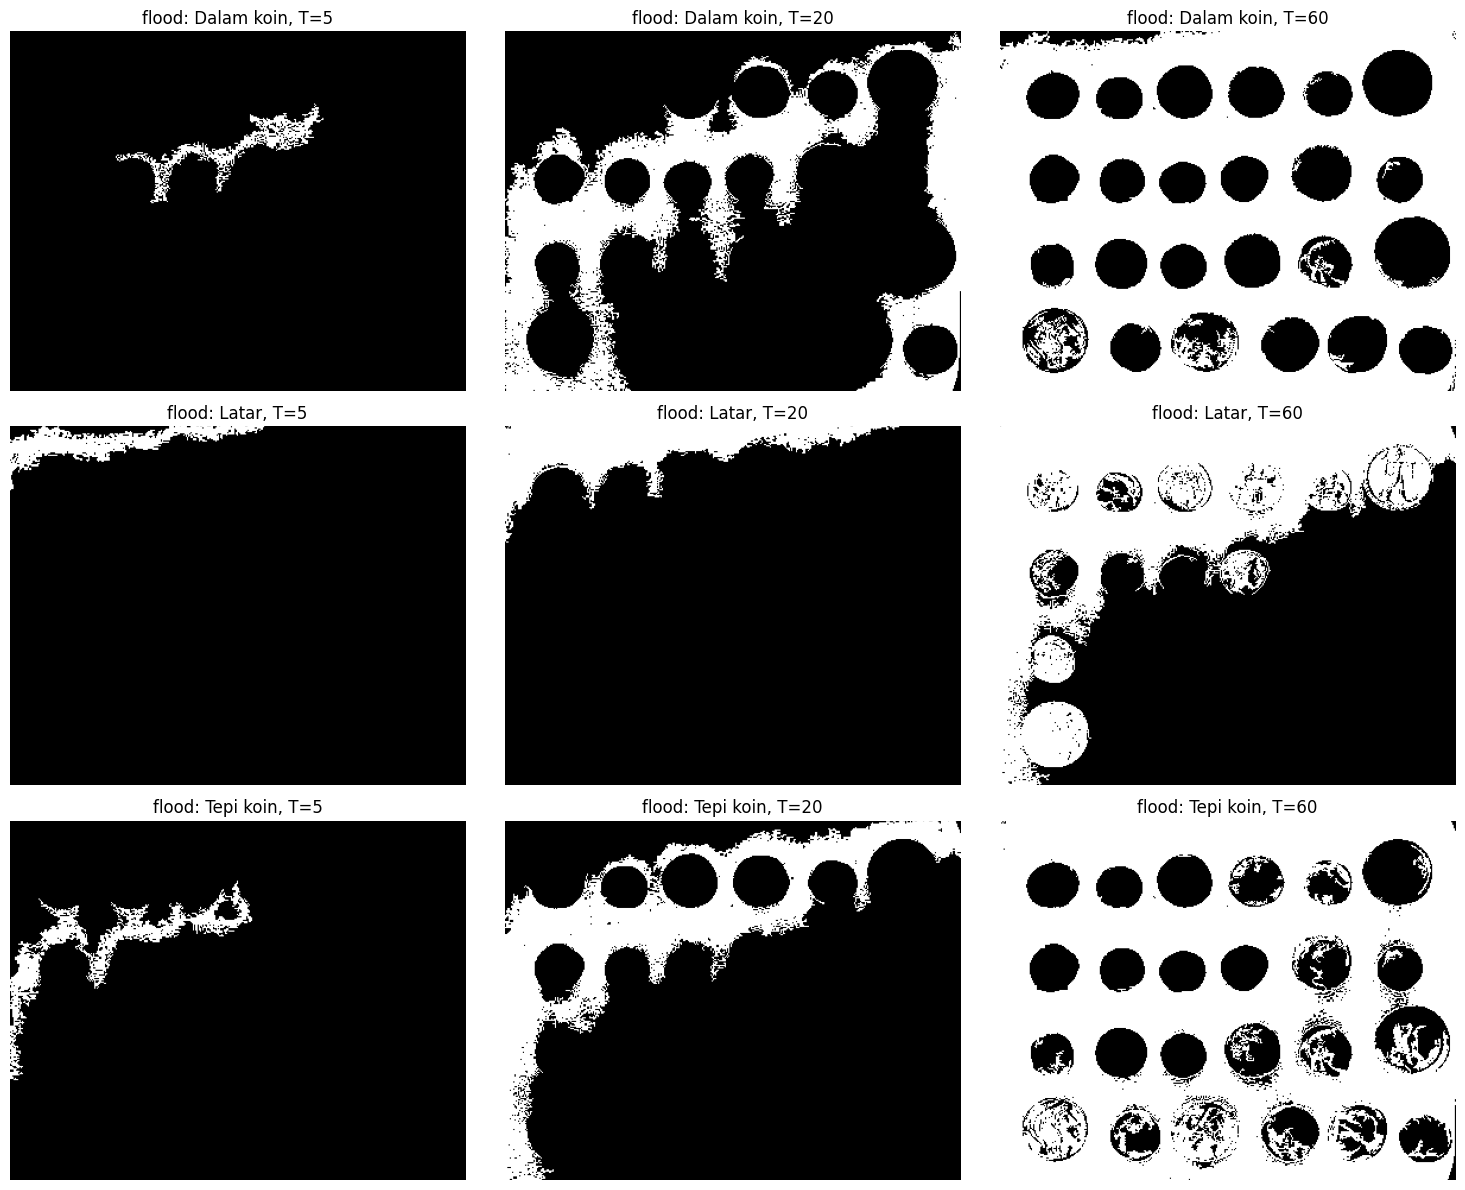

In [ ]:
coins = data.coins()

def region_growing(gray, seed, tolerance):
    h, w = gray.shape
    sy, sx = seed
    seed_value = float(gray[sy, sx])
    region_sum = seed_value
    region_count = 1
    mask = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)
    mask[sy, sx] = True
    visited[sy, sx] = True
    queue = [(sy, sx)]
    while queue:
        y, x = queue.pop(0)
        region_mean = region_sum / region_count
        diterima = mask[y, x] or abs(float(gray[y, x]) - region_mean) < tolerance
        if diterima:
            if not mask[y, x]:
                mask[y, x] = True
                region_sum += float(gray[y, x])
                region_count += 1
            for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                ny, nx = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                    visited[ny, nx] = True
                    queue.append((ny, nx))
    return mask

# Seed contoh: koin, latar, dan tepi.
seeds = {'Dalam koin': (100, 150), 'Latar': (20, 20), 'Tepi koin': (95, 120)}
tolerances = [5, 20, 60]
plt.figure(figsize=(15, 12))
for row, (seed_name, seed) in enumerate(seeds.items()):
    for col, tolerance in enumerate(tolerances):
        mask = region_growing(coins, seed, tolerance)
        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(mask, cmap='gray')
        plt.title(f'{seed_name}, T={tolerance}')
        plt.axis('off')
plt.tight_layout()
plt.show()

# flood() memakai toleransi terhadap intensitas seed dan keterhubungan piksel.
plt.figure(figsize=(15, 12))
for row, (seed_name, seed) in enumerate(seeds.items()):
    for col, tolerance in enumerate(tolerances):
        mask = segmentation.flood(coins, seed, tolerance=tolerance)
        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(mask, cmap='gray')
        plt.title(f'flood: {seed_name}, T={tolerance}')
        plt.axis('off')
plt.tight_layout()
plt.show()

## 5. Segmentasi Warna Biru pada KTP


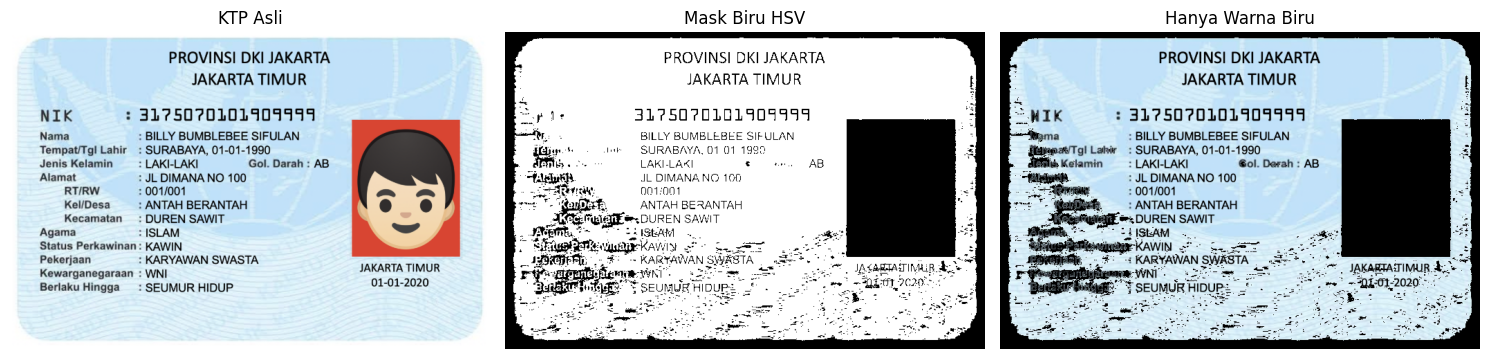

In [ ]:
if os.path.exists(PATH_KTP):
    ktp = cv.imread(PATH_KTP)
    hsv = cv.cvtColor(ktp, cv.COLOR_BGR2HSV)
    H, S, V = cv.split(hsv)
    kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
    mask_biru = (kelompok_biru.astype(np.uint8) * 255)
    hanya_biru = cv.bitwise_and(ktp, ktp, mask=mask_biru)
    tampilkan([ktp, mask_biru, hanya_biru], ['KTP Asli', 'Mask Biru HSV', 'Hanya Warna Biru'], cols=3)
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg milik sendiri dan jalankan ulang sel ini.')

### Pelengkap: K-Means pada Warna KTP
K-Means mengelompokkan piksel berdasarkan kedekatan warna. Cluster yang paling dekat dengan warna biru dipertahankan sebagai segmentasi warna biru.

Pusat cluster RGB:
[[212 233 245]
 [ 43  45  46]
 [215  69  50]
 [149 153 155]]
Cluster biru terpilih: 0


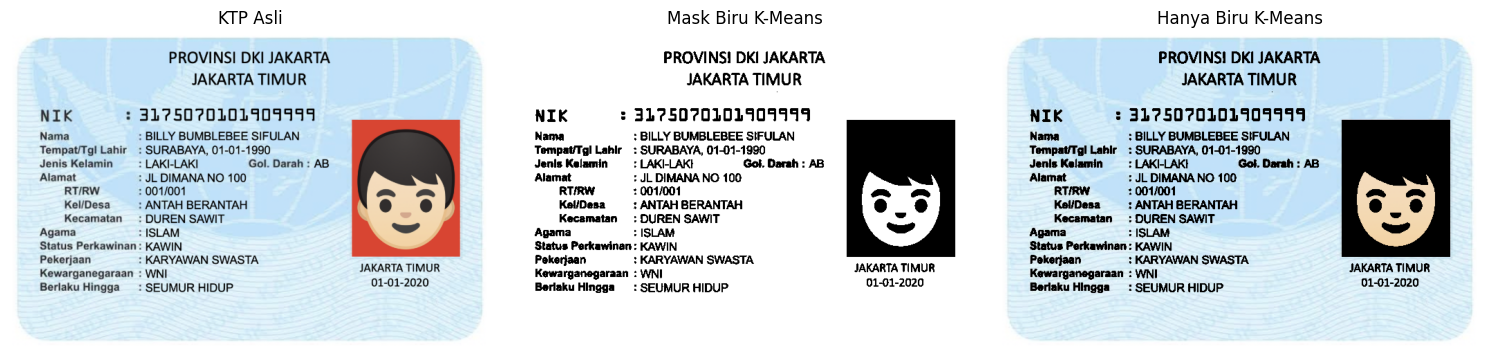

In [ ]:
if os.path.exists(PATH_KTP):
    from sklearn.cluster import KMeans

    ktp_rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)
    piksel = np.float32(ktp_rgb.reshape((-1, 3)))
    k = 4
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(piksel)
    centers = kmeans.cluster_centers_

    # Warna biru memiliki komponen B relatif tinggi dibanding R dan G.
    blue_score = centers[:, 2] - (centers[:, 0] + centers[:, 1]) / 2
    blue_cluster = int(np.argmax(blue_score))
    mask_kmeans = (labels == blue_cluster).astype(np.uint8).reshape(ktp.shape[:2]) * 255
    ktp_blue_kmeans = cv.bitwise_and(ktp, ktp, mask=mask_kmeans)

    print('Pusat cluster RGB:')
    print(np.uint8(centers))
    print(f'Cluster biru terpilih: {blue_cluster}')
    tampilkan([ktp, mask_kmeans, ktp_blue_kmeans], ['KTP Asli', 'Mask Biru K-Means', 'Hanya Biru K-Means'], cols=3)
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg untuk menjalankan K-Means.')

## 6. Tugas Kelompok (D2): OCR


In [ ]:
!apt-get install -y tesseract-ocr tesseract-ocr-ind > /dev/null 2>&1
!pip install -q pytesseract

import pytesseract
import pandas as pd
from IPython.display import display

print('Tesseract:', pytesseract.get_tesseract_version())

Tesseract: 5.3.4


### Daftar Citra KTP Anggota
Nama file dicari otomatis di folder Drive. Sesuaikan bila nama berbeda.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, segmentation

BASE = globals().get('BASE', '/content/drive/MyDrive/PCVK_2026')
def kandidat_ktp(nama):
    dasar = [f'ktp {nama}', f'ktp_{nama}', f'Ktp {nama.capitalize()}', f'ktp{nama}']
    ekstensi = ['.jpeg']
    kandidat = []
    for d in dasar:
        for e in ekstensi:
            kandidat.append(os.path.join(BASE, d + e))
            kandidat.append('/content/' + d + e)
    return kandidat

def cari_citra(kandidat):
    for path in kandidat:
        if os.path.exists(path):
            return path
    return kandidat[0]

KTP_FILES = {
    'Rifo': cari_citra(kandidat_ktp('rifo')),
    'Adam': cari_citra(kandidat_ktp('adam')),
    'Triya': cari_citra(kandidat_ktp('triya')),
}

for nama, path in KTP_FILES.items():
    print(f'{nama:6s}:', path, '(ada)' if os.path.exists(path) else '(belum ada)')

Rifo  : /content/drive/MyDrive/PCVK_2026/Ktp Rifo.jpeg (ada)
Adam  : /content/drive/MyDrive/PCVK_2026/Ktp Adam.jpeg (ada)
Triya : /content/drive/MyDrive/PCVK_2026/Ktp Triya.jpeg (ada)


### Fungsi Bantu
Semua citra disamakan ukurannya sebelum OCR. Kedua metode thresholding memakai citra grayscale.

In [ ]:
UKURAN = (900, 600)

def siapkan_citra(path, ukuran=UKURAN):
    img = cv.imread(path)
    img = cv.resize(img, ukuran, interpolation=cv.INTER_AREA)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    return img, gray

def otsu_library(gray):
    t, biner = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    return biner, int(t)

def adaptive_library(gray, block=11, C=2):
    return cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv.THRESH_BINARY, block, C)

def baca_teks(img, psm=6, lang='ind'):
    return pytesseract.image_to_string(img, lang=lang, config=f'--psm {psm}')

def gambar_kotak(img, conf_min=60, lang='ind', psm=6):
    canvas = cv.cvtColor(img, cv.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    data = pytesseract.image_to_data(img, lang=lang, config=f'--psm {psm}',
                                     output_type=pytesseract.Output.DICT)
    for i, teks in enumerate(data['text']):
        if teks.strip() and float(data['conf'][i]) > conf_min:
            x, y = data['left'][i], data['top'][i]
            w, h = data['width'][i], data['height'][i]
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return canvas

def rata_confidence(img, lang='ind', psm=6):
    data = pytesseract.image_to_data(img, lang=lang, config=f'--psm {psm}',
                                     output_type=pytesseract.Output.DICT)
    nilai = []
    for c in data['conf']:
        try:
            c = float(c)
        except (TypeError, ValueError):
            continue
        if c >= 0:
            nilai.append(c)
    return round(sum(nilai) / len(nilai), 2) if nilai else 0.0

def item_cocok(acuan, teks):
    teks_lower = teks.lower()
    return sum(1 for kata in acuan if kata.lower() in teks_lower)

### Perbandingan OCR per KTP
Tiga citra ditampilkan berdampingan, diikuti teks hasil OCR dan kotak hijau (confidence > 60) tiap metode.

KTP Rifo  (Otsu T=120)
--- OCR Berwarna ---
|
PROVINSI JAWA TIMUR
z KABUPATEN LUMAJANG
NIK : sa
Nama RIFO ANGGI BARBARA DANUARTA
Tempat/Tgi Lahir - LUMAJANG, 18-11-2005
Jenis kelamin LAKI-LAKI Gol. Darah
Alamat DSN. SIDORUKUN - -
RTRW : 001/004
Kol/Desa : GUCIALIT
Kecamatan : GUCIALIT
Agama : ISLAM ai
Status Perkawinan BELUM KAWIN
Pekerjaan PELAJAR/MAHASISWA LUMAJANG
Kewarganegaraan WNI 30-01-2023
Bertiaku Hingga SEUMUR HIDUP
| - |
: | 4F AE

--- OCR Otsu ---
PROVINSI JAWA TIMUR |
KABUPATEN | UMAJANG
TU |
Nama RF O ANGGI BARBAHA DAMUARTA
TampatIgilahis LUMAJANG, 18 11.-7005
Jeris kelamin LAKI-LAKI "201 Umuh
Mama DSN SIDORUKLN
RTRW c01/004 “
KollDosa — GUCIALIT
Kecamatan GUGIALIT -
Agarna ISL AM -
Sintua Perkaminan BELUM KAWIN
Pekerjaan - PELAJAR/MAHASISWA LUMAJANG
Kewarganegaraan WN! 2022
Bariaku Hingga. SEUMURHIDUP z.
13

--- OCR Adaptive ---
HP Hn BA ana Tenan
MANA —. - - ka - . 4 Ka egnaN 21 E
Pa Ea Me 5 Ii
5 PROVINSIJAWA HMUR
PA ai gt Se aan
5Nama” 5: &RIFOANGGIBARBARADANUARTA- —.|

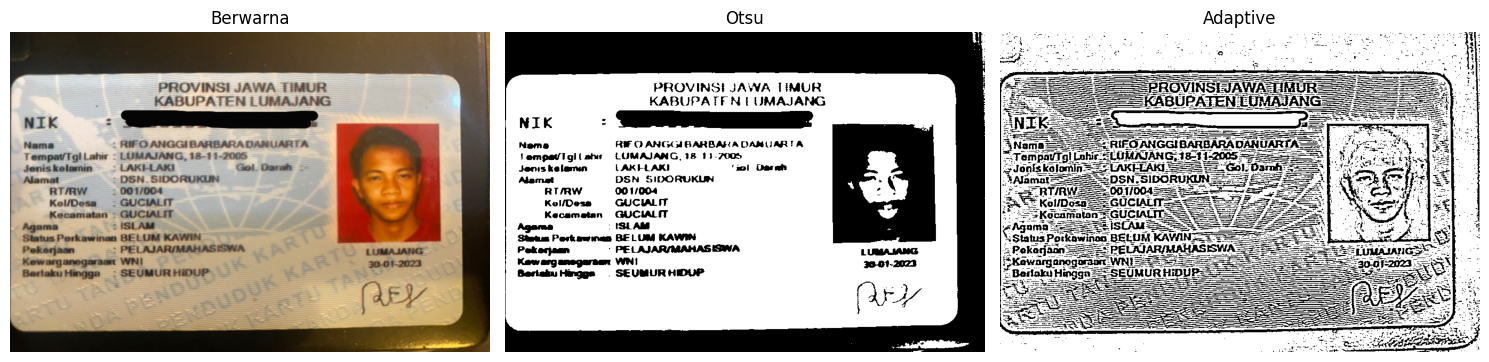

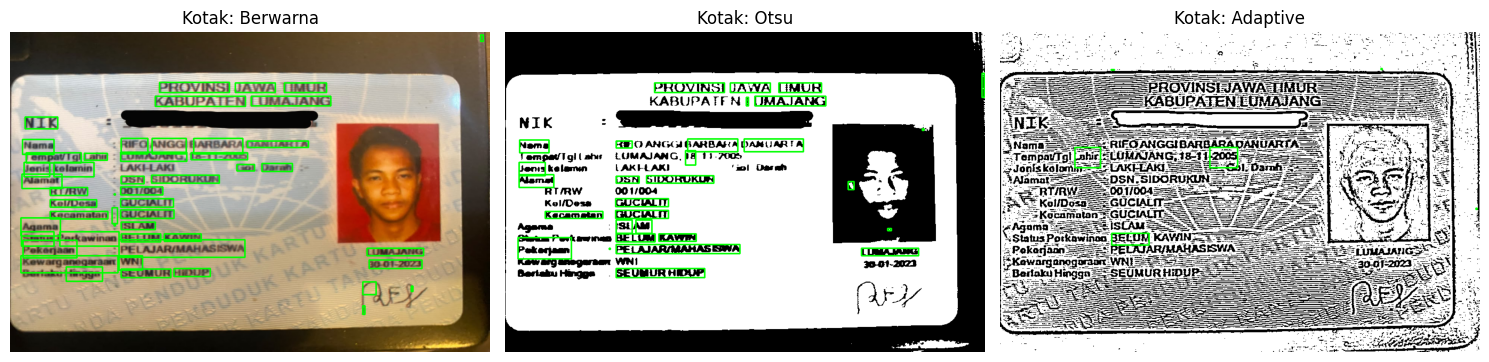

KTP Adam  (Otsu T=118)
--- OCR Berwarna ---
st -
— Ta PP”
0 PROVINSIJAWATIMUR
“NIK (3 HSO SO Ik N50DO2 — 3
aga ADAM ARSYAD FAIZIN (VITINHA) : 8.
Luar SELIAR 3 Ta ena .
Nami 0 PSG “ng baja
| Fasa Ia
Tn LI
Perta an aa nan GE ana
aa Maan SEUMUR MDUP oran
- To

--- OCR Otsu ---
d Na...
mm —MN Lal . SP "
PROVINSI JAWA TIMUR
KABUPATEN BLITAR
"NIK 1 350510.-1ma 50002
Nama : MOCH. ADAM ARSYAD FAIZIN (VITINH
Tempattg! Lahir "BLITAR, 11-11-2005 “Mi:
senigkalamin —: LAKI-LAKI Gol. Darah :-
Lo Mamat . PSG 5
: RTRW: 003002 KA SI
LN KevDasa “i KUNINGAN - »..
4 Kecamatan. : KANIGORG .. ..
: Agama LISLAM 1. Hn
Status Perkawinan: BELUMKAWIN - ....... e/ |
Pekenaan : PELAJAH/MAHASISWA BLITAR
“ndk Keras : WNI -
ec” Bertar | igo SEUMUR HIDUP - 22-07 2024
Lagaat PCvK

--- OCR Adaptive ---
Na ms ma
Pena Sig ik na Pa eng AAN
ama nyaman Di

Pepe 3  BROVINSIJAWA TIMUR 5 NY

ba Ke 3 KABUPATENBLITAR ta N

SAINIK, S ASOSLORGENSUODO Ss —-—.. 1

AAA ai aka sa Dus

F#m ee 2 S2 MOCH- ADAM ARSYAD FAIZIN (VITINHA) : pe

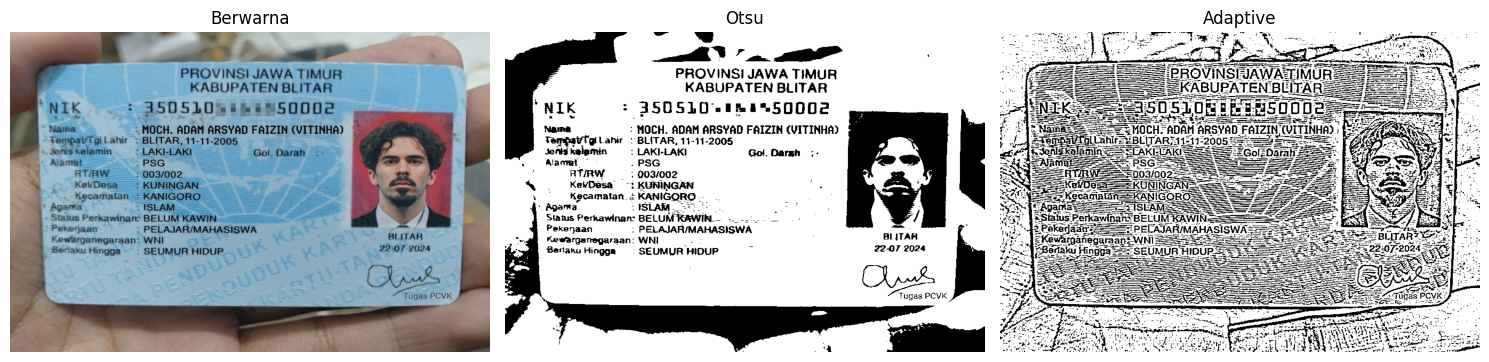

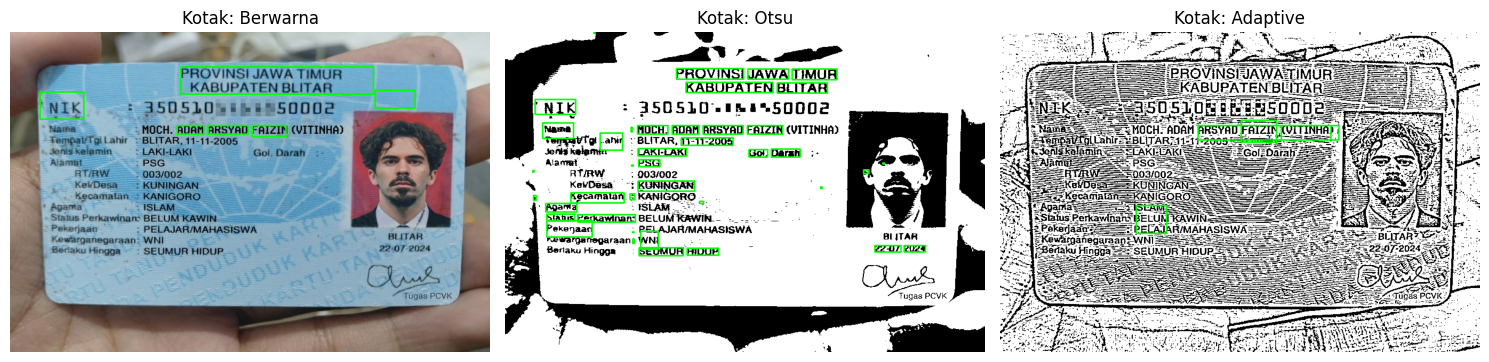

KTP Triya  (Otsu T=121)
--- OCR Berwarna ---
FE —w————-.——— AA ————— — —— 5 —— X
000 KABUPATENKEDIRI —
oo ai ay aa
: Hama — MEMTATRIYAYUHANA
—TempatTgi Lahir 2m mam ii
& PEREMPUAN arah
LA TP
5 Xesmtan egg 10
— Status Perkawinan BELUM KAWIN ———————
Pekerjaan —— - PELAYAR/MAHASISWA —- —
Kewarganegaraan: WNI —-————— .- -— 2 La
k F2 -

--- OCR Otsu ---
— N
PROVINSI! JAWA TIMUR
KABUPATEN KEDIRI
NIK : .. .. "..
Haa : MEVITA TRIYA YULIANA
PempatTgi Lah moon.
domekalamin PEREMPUAN” Gol Darah :-
Alamat Ta ——
Ama P3 Da
Kevbasa— Ia ae Eh
Kebamatar mo TI
Agama ASEAR Oa SO
Status Perkawinan BELUM KAWIN. --.
Pekerjaan : PELAJAR/MAHASISWA —.-
Kewarganegaraan WNI
Berlaku Hingga: SEUMUR HIDUP ...
n
Pan
La
bk ”

--- OCR Adaptive ---
Ps PE, TT A5
ee ee — PROVINSIJAWATIMURS— 2— P —-
PA ra Te  ——
Se  KABUPATENKEDIRP
ee anne —————
2: #REMATATAI ANA PE —
ae “th 2
En - Pe Le LO
“en Bu erat”
Agama ba apn P
“pekemaan 25 -PEPMARMAHASISWA2 mena
EEBeraku Hinggas 2 SEUMUR HipUp Ea P2 MN TI
Sa oa aa Ar an
Be 5 AA — 

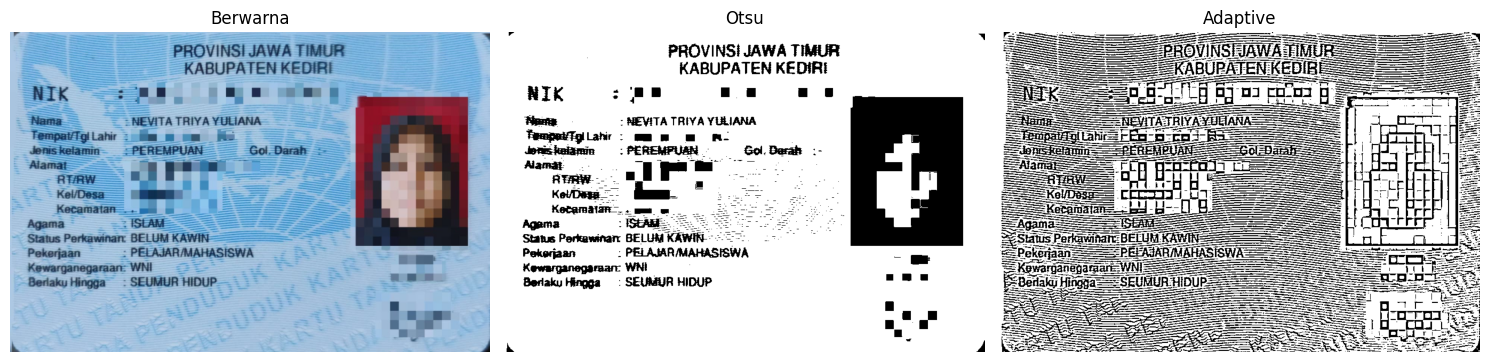

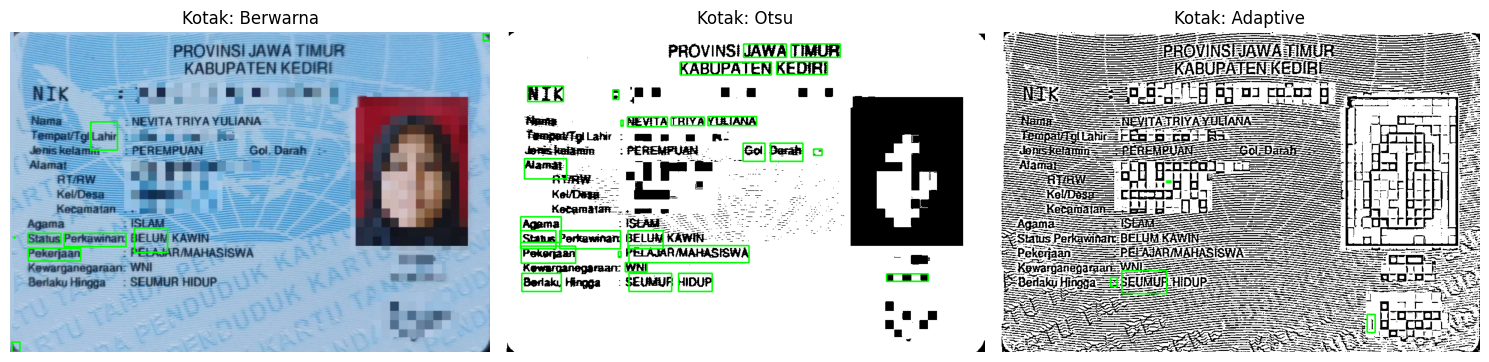

In [ ]:
teks_ocr = {}

for nama, path in KTP_FILES.items():
    if not os.path.exists(path):
        print(f'[{nama}] file belum tersedia: {path}')
        continue

    warna, gray = siapkan_citra(path)
    otsu_img, otsu_t = otsu_library(gray)
    adap_img = adaptive_library(gray)

    teks_ocr[nama] = {
        'Berwarna': baca_teks(warna),
        'Otsu': baca_teks(otsu_img),
        'Adaptive': baca_teks(adap_img),
    }

    print('=' * 70)
    print(f'KTP {nama}  (Otsu T={otsu_t})')
    print('=' * 70)
    for label in ['Berwarna', 'Otsu', 'Adaptive']:
        print(f'--- OCR {label} ---')
        print(teks_ocr[nama][label].strip())
        print()

    tampilkan([warna, otsu_img, adap_img],
              ['Berwarna', 'Otsu', 'Adaptive'], cols=3)
    tampilkan([gambar_kotak(warna), gambar_kotak(otsu_img), gambar_kotak(adap_img)],
              ['Kotak: Berwarna', 'Kotak: Otsu', 'Kotak: Adaptive'], cols=3)

### Tabel Perbandingan 10 Kata Acuan
Isi `ACUAN` dengan 10 kata/angka yang terlihat jelas pada tiap KTP. Tanda `v` berarti terbaca tepat, `x` berarti tidak.

In [ ]:
ACUAN = {
    'Rifo': ['RIFO', 'ANGGI', 'BARBARA', 'DANUARTA', 'LUMAJANG',
         '18-11-2005', 'LAKI-LAKI', 'ISLAM', 'GUCIALIT', 'WNI'],
    'Adam': ['MOCH', 'ADAM', 'ARSYAD', 'FAIZIN', 'BLITAR',
             '11-11-2005', 'LAKI-LAKI', 'KANIGORO', 'ISLAM', 'WNI'],
    'Triya': ['NEVITA', 'TRIYA', 'YULIANA', 'KEDIRI', 'PEREMPUAN',
              'ISLAM', 'BELUM', 'KAWIN', 'PELAJAR', 'WNI'],
}

for nama, path in KTP_FILES.items():
    if nama not in teks_ocr:
        continue
    acuan = ACUAN.get(nama, [])
    if not acuan:
        print(f'[{nama}] ACUAN masih kosong. Isi daftar kata acuan lalu jalankan ulang.')
        continue
    baris = []
    for i, kata in enumerate(acuan, 1):
        baris.append([
            i, kata,
            'v' if kata.lower() in teks_ocr[nama]['Berwarna'].lower() else 'x',
            'v' if kata.lower() in teks_ocr[nama]['Otsu'].lower() else 'x',
            'v' if kata.lower() in teks_ocr[nama]['Adaptive'].lower() else 'x',
        ])
    df = pd.DataFrame(baris, columns=['No.', 'Teks sebenarnya', 'OCR berwarna', 'OCR Otsu', 'OCR Adaptive'])
    print(f'Tabel perbandingan KTP {nama}')
    display(df)

Tabel perbandingan KTP Rifo


,No.,Teks sebenarnya,OCR berwarna,OCR Otsu,OCR Adaptive
0,1,RIFO,v,x,v
1,2,ANGGI,v,v,v
2,3,BARBARA,v,x,v
3,4,DANUARTA,v,x,v
4,5,LUMAJANG,v,v,v
5,6,18-11-2005,v,x,x
6,7,LAKI-LAKI,v,v,x
7,8,ISLAM,v,x,v
8,9,GUCIALIT,v,v,x
9,10,WNI,v,x,v


Tabel perbandingan KTP Adam


,No.,Teks sebenarnya,OCR berwarna,OCR Otsu,OCR Adaptive
0,1,MOCH,x,v,v
1,2,ADAM,v,v,v
2,3,ARSYAD,v,v,v
3,4,FAIZIN,v,v,v
4,5,BLITAR,x,v,v
5,6,11-11-2005,x,v,x
6,7,LAKI-LAKI,x,v,x
7,8,KANIGORO,x,x,v
8,9,ISLAM,x,v,v
9,10,WNI,x,v,v


Tabel perbandingan KTP Triya


,No.,Teks sebenarnya,OCR berwarna,OCR Otsu,OCR Adaptive
0,1,NEVITA,x,x,x
1,2,TRIYA,v,v,x
2,3,YULIANA,x,v,x
3,4,KEDIRI,v,v,x
4,5,PEREMPUAN,v,v,x
5,6,ISLAM,x,x,x
6,7,BELUM,v,v,x
7,8,KAWIN,v,v,x
8,9,PELAJAR,x,v,x
9,10,WNI,v,v,x


### Ringkasan Kecocokan dan Confidence

In [ ]:
ringkasan = []

for nama, path in KTP_FILES.items():
    if nama not in teks_ocr:
        continue
    acuan = ACUAN.get(nama, [])
    warna, gray = siapkan_citra(path)
    otsu_img, _ = otsu_library(gray)
    adap_img = adaptive_library(gray)
    pasangan = [('Berwarna', warna), ('Otsu', otsu_img), ('Adaptive', adap_img)]
    for label, img in pasangan:
        teks = teks_ocr[nama][label]
        cocok = item_cocok(acuan, teks)
        persen = round(100 * cocok / len(acuan), 1) if acuan else 0.0
        ringkasan.append([f'{nama} - {label}', cocok, persen, rata_confidence(img)])

df_ringkasan = pd.DataFrame(ringkasan, columns=['Citra masukan OCR', 'Item terbaca tepat', 'Kecocokan (%)', 'Rata-rata confidence'])
display(df_ringkasan)

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Rifo - Berwarna,10,100.0,74.61
1,Rifo - Otsu,4,40.0,57.38
2,Rifo - Adaptive,7,70.0,18.68
3,Adam - Berwarna,3,30.0,25.31
4,Adam - Otsu,9,90.0,51.64
5,Adam - Adaptive,8,80.0,16.47
6,Triya - Berwarna,6,60.0,28.62
7,Triya - Otsu,8,80.0,47.43
8,Triya - Adaptive,0,0.0,20.54


### Pertanyaan Analisis
1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

**Jawaban:**
1. Tidak ada satu metode yang selalu paling tepat. Rifo: Berwarna 100% (Otsu hanya 40%). Adam: Otsu 90% (Berwarna 30%). Triya: Otsu 80% (Berwarna 60%). Rata-rata kecocokan: Otsu = (40+90+80)/3 = 70%; Berwarna = (100+30+60)/3 = 63,3%; Adaptive = (70+80+0)/3 = 50%. Jadi secara rata-rata Otsu paling tepat, tetapi Berwarna unggul pada KTP Rifo.
2. Kesalahan yang terlihat:
- Rifo-Otsu: DANUARTA → DAMUARTA (N→M); LUMAJANG → UMAJANG (huruf L hilang); 18-11-2005 → 18 11.-7005 (2→7, 0→o).
- Rifo-Adaptive: PROVINSI JAWA TIMUR → PROVINSIJAWA HMUR (T→H); LAKI-LAKI → LAKELAKI.
- Rifo-Berwarna: NIK : sa (angka NIK tidak terbaca).
- Triya-Adaptive: 0 item cocok, hampir semua teks kacau.
3. Tidak selalu. Segmentasi meningkatkan pada Adam (30%→90%) dan Triya (60%→80%), tetapi menurunkan pada Rifo (100%→40%). Adaptive justru sering memburuk (Triya 0%). Efektivitas bergantung pada kualitas citra asli dan karakter latar.
4. Latar KTP berwarna biru dengan pola guilloche dan teks gelap/terang. Pada Rifo latar bersih → citra berwarna terbaik. Pada Adam/Triya ada bayangan/pantulan dan pola latar kuat sehingga OCR citra berwarna terganggu dan thresholding membantu. Namun adaptive threshold pada latar berpola menghasilkan banyak noise sehingga huruf terpecah (Triya Adaptive = 0%).
5. Tidak selalu konsisten. Rifo-Berwarna: confidence tertinggi (74,61) sekaligus kecocokan tertinggi (100%) → konsisten. Tetapi Rifo-Adaptive: confidence rendah (18,68) justru kecocokan (70%) lebih tinggi daripada Otsu (confidence 57,38; kecocokan 40%) → tidak konsisten. Confidence mengukur keyakinan mesin, bukan benar/tidaknya terhadap acuan.

## Kesimpulan
Global threshold cocok saat pencahayaan merata dan histogram terpisah. Adaptive threshold lebih sesuai untuk pencahayaan tidak merata karena ambangnya dihitung dari lingkungan lokal. Otsu memilih ambang otomatis berdasarkan histogram. Region growing mempertimbangkan keterhubungan piksel, sedangkan masking HSV dapat mengekstrak kelompok warna tertentu seperti biru pada KTP.